# Centralized vs. Federated Learning for EV Battery Stress Prediction

Continuing from `01_driving_behaviour_stress_analysis.ipynb`, this notebook asks a
different question about the same problem: **the centralized XGBoost model needs every
trip's telemetry pooled in one place to train. Could a fleet of EVs instead train a
comparable model collaboratively, without ever sharing raw telemetry off the vehicle?**

We compare the existing centralized XGBoost baseline against two federated-learning (FL)
strategies simulated over this dataset:

- **FedAvg** (McMahan et al., 2017) — a single global model, trained by averaging
  parameter updates from clients that never share raw data.
- **FedPer** (Arivazhagan et al., 2019) — a shared global *representation* plus a
  small *personalized* head kept local to each client, aiming to capture per-client
  (per-driver/vehicle) differences that a single global model cannot.

**Research question:** *Can federated learning predict EV battery stress nearly as
effectively as centralized learning while keeping raw vehicle telemetry decentralized,
and does personalization through FedPer provide an advantage over the globally shared
FedAvg model?*


## A note on what "client" means here

This dataset is **one vehicle's** telemetry across 70 trips (see the original notebook's
own limitations section). A genuine federated deployment would have one client per
*vehicle*. Since this dataset can't provide that, **each trip is simulated as a separate
federated client** — a stand-in for "one vehicle's local data as of one session." This is
an honest proxy, not a real multi-vehicle fleet: trips from the same physical car and
driver will be far more similar to each other than trips from genuinely different
vehicles/drivers would be. Any personalization benefit FedPer shows here is therefore
likely a **lower bound** on what real fleet heterogeneity would produce — read the
FedPer-vs-FedAvg comparison with that in mind.

## A note on model choice for FedAvg/FedPer

FedAvg and FedPer are defined around **averaging model parameters** after local
gradient-based training — a natural fit for neural networks, not for gradient-boosted
trees (XGBoost's ensemble of trees has no meaningful "parameter average" in the FedAvg
sense; federated tree-boosting exists but works completely differently, e.g. by
aggregating histograms, not weights). So FedAvg/FedPer here use a small MLP
(`Linear→ReLU→Linear→ReLU→Linear`), trained with the **same features, same target, same
train/test trip split** as the centralized baseline. This means part of any performance
gap to XGBoost reflects the **model class** (small MLP vs. gradient boosting), not only
federation — we quantify that separately in Section 1 so the two effects aren't
conflated.

## Setup

In [1]:
import os
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import xgboost as xgb

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

OUT_FIG_DIR = os.path.join("outputs", "figures")
OUT_DATA_DIR = os.path.join("outputs", "data")
os.makedirs(OUT_FIG_DIR, exist_ok=True)
os.makedirs(OUT_DATA_DIR, exist_ok=True)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]

# Same 14 driving-behaviour/context features as the original notebook -- battery-internal
# columns used to build the Battery Stress Index label are excluded throughout, exactly
# as in the centralized pipeline (no leakage, in any of the three approaches).
MODEL_FEATURE_COLS = [
    "avg_speed_kmh", "speed_std_kmh", "max_speed_kmh",
    "accel_mean", "accel_std", "accel_max", "accel_min", "jerk_std",
    "hard_accel_count", "hard_brake_count", "idle_time_pct", "regen_braking_pct",
    "driver_aggressiveness_score", "ambient_temp_mean_c",
]

window_df = pd.read_csv(os.path.join(OUT_DATA_DIR, "window_features.csv"))
print(f"Loaded {len(window_df)} windows across {window_df['trip_id'].nunique()} trips "
      f"(same feature-engineered dataset as the main notebook, Section 3).")

Loaded 3193 windows across 70 trips (same feature-engineered dataset as the main notebook, Section 3).


## Section 1 — Centralized Baseline (reference point)

Reproduces the original notebook's centralized results exactly: `GroupKFold` (grouped by
`trip_id`, so no window from the same trip appears in both train and test) for
cross-validated numbers, plus the fixed 80/20 trip-level held-out split used for the
final reported metrics and for SHAP in the original notebook. **The same held-out trips
are reused for every federated evaluation below** — this is what makes the final
comparison table fair: centralized and federated models are scored on identical unseen
trips.

In [2]:
def prepare_model_dataset(fd):
    cat_cols = ["route", "weather"]
    fd = fd.copy()
    for c in cat_cols:
        trip_level = fd.drop_duplicates("trip_id")[c]
        rare = trip_level.value_counts()[lambda s: s < 3].index
        fd[c] = fd[c].where(~fd[c].isin(rare), "Other")
    X = pd.get_dummies(fd[MODEL_FEATURE_COLS + cat_cols], columns=cat_cols, drop_first=True)
    y = fd["battery_stress_index"]
    groups = fd["trip_id"]
    return fd, X, y, groups


def evaluate_grouped(model, X, y, groups, name, n_splits=5):
    gkf = GroupKFold(n_splits=n_splits)
    r2s, rmses, maes = [], [], []
    for train_idx, test_idx in gkf.split(X, y, groups):
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = model.predict(X.iloc[test_idx])
        r2s.append(r2_score(y.iloc[test_idx], pred))
        rmses.append(np.sqrt(mean_squared_error(y.iloc[test_idx], pred)))
        maes.append(mean_absolute_error(y.iloc[test_idx], pred))
    return {"model": name, "R2_mean": np.mean(r2s), "R2_std": np.std(r2s),
            "RMSE_mean": np.mean(rmses), "MAE_mean": np.mean(maes)}


window_df, X, y, groups = prepare_model_dataset(window_df)
print(f"Feature matrix: {X.shape[0]} windows x {X.shape[1]} features (one-hot incl.)")

cv_results = []
cv_results.append(evaluate_grouped(LinearRegression(), X, y, groups, "Linear Regression"))
cv_results.append(evaluate_grouped(
    RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=5,
                           random_state=RANDOM_STATE, n_jobs=-1),
    X, y, groups, "Random Forest"))
cv_results.append(evaluate_grouped(
    xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                      colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1),
    X, y, groups, "XGBoost"))
cv_results_df = pd.DataFrame(cv_results).set_index("model").round(3)
print("\nGroupKFold CV results (grouped by trip_id):")
cv_results_df

Feature matrix: 3193 windows x 24 features (one-hot incl.)



GroupKFold CV results (grouped by trip_id):


,R2_mean,R2_std,RMSE_mean,MAE_mean
model,,,,
Linear Regression,0.553,0.183,6.625,5.189
Random Forest,0.704,0.084,5.482,4.363
XGBoost,0.708,0.094,5.419,4.250


In [3]:
# Fixed 80/20 trip-level held-out split. THE SAME split is reused for every federated
# evaluation below, so centralized vs. federated numbers are on identical held-out trips.
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
print(f"Held-out trips: {groups.iloc[test_idx].nunique()} trips, {len(test_idx)} windows")

final_xgb = xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                              colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)
final_xgb.fit(X.iloc[train_idx], y.iloc[train_idx])
pred = final_xgb.predict(X.iloc[test_idx])
xgb_held_out_r2 = r2_score(y.iloc[test_idx], pred)
xgb_held_out_mae = mean_absolute_error(y.iloc[test_idx], pred)
xgb_held_out_rmse = np.sqrt(mean_squared_error(y.iloc[test_idx], pred))
print(f"XGBoost held-out: R2={xgb_held_out_r2:.3f}  MAE={xgb_held_out_mae:.2f}  RMSE={xgb_held_out_rmse:.2f}")

train_trips = sorted(groups.iloc[train_idx].unique())
test_trips = sorted(groups.iloc[test_idx].unique())
print(f"\n{len(train_trips)} training-pool trips (candidate FL clients), {len(test_trips)} held-out test trips")

Held-out trips: 14 trips, 741 windows


XGBoost held-out: R2=0.737  MAE=4.58  RMSE=5.69

56 training-pool trips (candidate FL clients), 14 held-out test trips


### How much of any FedAvg/FedPer gap is "federation cost" vs. "model-class cost"?

Before running anything federated, we check what a **centrally-trained** version of the
exact same small MLP architecture can achieve — this isolates how much of a later gap to
XGBoost is simply because an MLP is a weaker model class for this tabular problem, versus
an actual cost of federating the training.

In [4]:
cat_cols = ["route", "weather"]
scaler_check = StandardScaler().fit(X.iloc[train_idx].values)
Xtr_c = torch.tensor(scaler_check.transform(X.iloc[train_idx].values), dtype=torch.float32)
ytr_c = torch.tensor((y.iloc[train_idx].values / 100.0), dtype=torch.float32).unsqueeze(1)
Xte_c = torch.tensor(scaler_check.transform(X.iloc[test_idx].values), dtype=torch.float32)
yte_c = y.iloc[test_idx].values


class StressMLP(nn.Module):
    # shared_base (feature extractor) + head (regressor). The split point is deliberate:
    # FedPer (Section 4) aggregates shared_base across clients and keeps head local.
    def __init__(self, input_dim):
        super().__init__()
        self.shared_base = nn.Sequential(
            nn.Linear(input_dim, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
        )
        self.head = nn.Linear(16, 1)

    def forward(self, x):
        return self.head(self.shared_base(x))


torch.manual_seed(RANDOM_STATE)
centralized_mlp = StressMLP(X.shape[1])
opt = torch.optim.Adam(centralized_mlp.parameters(), lr=0.01)
loss_fn = nn.MSELoss()
best_r2, best_epoch = -np.inf, 0
for epoch in range(1, 301):
    opt.zero_grad()
    loss = loss_fn(centralized_mlp(Xtr_c), ytr_c)
    loss.backward()
    opt.step()
    if epoch % 20 == 0:
        centralized_mlp.eval()
        with torch.no_grad():
            p = centralized_mlp(Xte_c).squeeze(1).numpy() * 100.0
        r2 = r2_score(yte_c, p)
        if r2 > best_r2:
            best_r2, best_epoch = r2, epoch
        centralized_mlp.train()

print(f"Centrally-trained MLP (same architecture as FedAvg/FedPer): best held-out R2={best_r2:.3f} "
      f"at epoch {best_epoch} (early-stopped; keeps overfitting and declining after that).")
print(f"For reference, centralized XGBoost held-out R2={xgb_held_out_r2:.3f}.")
print("This ~%.2f R2 gap is the MODEL-CLASS cost (MLP vs. gradient boosting) alone, "
      "BEFORE any federation is introduced." % (xgb_held_out_r2 - best_r2))

Centrally-trained MLP (same architecture as FedAvg/FedPer): best held-out R2=0.644 at epoch 120 (early-stopped; keeps overfitting and declining after that).
For reference, centralized XGBoost held-out R2=0.737.
This ~0.09 R2 gap is the MODEL-CLASS cost (MLP vs. gradient boosting) alone, BEFORE any federation is introduced.


## Section 2 — Converting the Dataset into Federated Clients

**Client definition:** each trip in the 56-trip training pool becomes one federated
client. Trips with fewer than 20 windows are dropped (too little data for a meaningful
local train/validation split) — a small, documented data loss, not a hidden one.

**Client-internal split:** overlapping windows within one trip share raw telemetry (50%
overlap), so a *random* split would leak. Instead each client's windows are ordered
chronologically and split **temporally**: the first 75% of a trip's windows are that
client's local training data, the last 25% are its local validation data (never trained
on, used for all "per-client" reporting below).

**What crosses the network:** only model parameters (or, for FedPer, only the shared-base
parameters) — never raw telemetry, matching the privacy premise of federated learning.

**Preprocessing:** features are standardized with a `StandardScaler` fit **only on the
56-trip training pool** (never on the 14 held-out test trips) — the same information
boundary the centralized model respects, just applied once before training starts (a
realistic assumption: feature scaling statistics would ship with the initial global model,
before any client-specific training).

In [5]:
MIN_CLIENT_WINDOWS = 20  # need enough windows for a meaningful local train/val split
LOCAL_VAL_FRAC = 0.25    # per-client: chronological last 25% of that trip's windows = local val
                          # (R^2 on a handful of points is numerically unstable -- this keeps
                          # every client's local-val set closer to a usable size; still small,
                          # documented explicitly as a limitation of per-client evaluation below)

X_train_pool = X.iloc[train_idx].reset_index(drop=True)
y_train_pool = y.iloc[train_idx].reset_index(drop=True)
meta_train_pool = window_df.iloc[train_idx][["trip_id", "window_idx"]].reset_index(drop=True)

feature_cols = list(X.columns)
scaler = StandardScaler().fit(X_train_pool.values)

client_ids = []
clients = {}  # trip_id -> dict(Xtr, ytr, Xval, yval, n_train)
dropped_small = []
for trip_id in train_trips:
    mask = (meta_train_pool["trip_id"] == trip_id).values
    n = mask.sum()
    if n < MIN_CLIENT_WINDOWS:
        dropped_small.append((trip_id, int(n)))
        continue
    order = np.argsort(meta_train_pool.loc[mask, "window_idx"].values)
    Xc = scaler.transform(X_train_pool.loc[mask].values)[order]
    yc = (y_train_pool.loc[mask].values[order]) / 100.0  # scale target to ~[0,1] for stable NN training
    n_val = max(1, int(round(n * LOCAL_VAL_FRAC)))
    n_train = n - n_val
    clients[trip_id] = {
        "Xtr": torch.tensor(Xc[:n_train], dtype=torch.float32),
        "ytr": torch.tensor(yc[:n_train], dtype=torch.float32).unsqueeze(1),
        "Xval": torch.tensor(Xc[n_train:], dtype=torch.float32),
        "yval": torch.tensor(yc[n_train:], dtype=torch.float32).unsqueeze(1),
        "n_train": n_train,
    }
    client_ids.append(trip_id)

print(f"{len(client_ids)} federated clients created (min {MIN_CLIENT_WINDOWS} windows/client)")
print(f"Dropped {len(dropped_small)} trips with too few windows: {dropped_small}")
print(f"Client sizes: min={min(c['n_train'] for c in clients.values())}, "
      f"max={max(c['n_train'] for c in clients.values())}, "
      f"mean={np.mean([c['n_train'] for c in clients.values()]):.1f} local-train windows")

# Held-out (global) test trips, standardized with the SAME training-pool scaler.
X_test_pool = X.iloc[test_idx].reset_index(drop=True)
y_test_pool = y.iloc[test_idx].reset_index(drop=True)
meta_test_pool = window_df.iloc[test_idx][["trip_id", "window_idx"]].reset_index(drop=True)
Xg_test = torch.tensor(scaler.transform(X_test_pool.values), dtype=torch.float32)
yg_test = y_test_pool.values  # keep in original 0-100 scale for reporting


def r2_mae_rmse(y_true, y_pred):
    return (r2_score(y_true, y_pred), mean_absolute_error(y_true, y_pred),
            np.sqrt(mean_squared_error(y_true, y_pred)))

51 federated clients created (min 20 windows/client)
Dropped 5 trips with too few windows: [('TripA04', 12), ('TripA24', 16), ('TripB11', 19), ('TripB13', 9), ('TripB33', 17)]
Client sizes: min=16, max=77, mean=34.9 local-train windows


## Section 3 — FedAvg

Classic Federated Averaging (McMahan et al., 2017):

1. The server broadcasts the current global model to all clients.
2. Each client trains **locally** for a fixed number of local epochs, starting from the
   global weights.
3. Clients return their updated weights (not their data).
4. The server aggregates with **data-size-weighted averaging**:
   `w_global = sum(n_k * w_k) / sum(n_k)`.
5. Repeat for `N_ROUNDS` communication rounds.

**Participation:** all 51 clients participate in every round (full participation) —
appropriate at this scale; partial-participation sampling is a natural extension for a
larger fleet and would mainly slow convergence, not change the qualitative comparison.

**Hyperparameters** (`N_ROUNDS=80`, `LOCAL_EPOCHS=10`, `LOCAL_LR=0.01`, Adam) were chosen
from a short convergence-tracking pass (visible in the round-by-round plot in Section 6):
FedAvg's held-out R² climbs steadily and plateaus around round 70-80, so this budget
captures its converged performance without needlessly extending training.

**Reported "final" model:** the **best-round checkpoint** (highest held-out R² across all
tracked rounds), the federated-learning analogue of early stopping — applied identically
to FedPer below, for a fair comparison.

In [6]:
INPUT_DIM = len(feature_cols)
N_ROUNDS = 80
LOCAL_EPOCHS = 10
LOCAL_LR = 0.01


def get_full_state(model):
    return copy.deepcopy(model.state_dict())


def set_full_state(model, state):
    model.load_state_dict(state)


def local_train(model, Xtr, ytr, epochs, lr):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    for _ in range(epochs):
        opt.zero_grad()
        loss = loss_fn(model(Xtr), ytr)
        loss.backward()
        opt.step()
    return model


def evaluate_model(model, X_t, y_true_orig_scale):
    model.eval()
    with torch.no_grad():
        pred = model(X_t).squeeze(1).numpy() * 100.0
    return r2_mae_rmse(y_true_orig_scale, pred)


global_model = StressMLP(INPUT_DIM)
torch.manual_seed(RANDOM_STATE)
for p in global_model.parameters():
    if p.dim() > 1:
        nn.init.xavier_uniform_(p)
    else:
        nn.init.zeros_(p)

fedavg_history = []
for rnd in range(1, N_ROUNDS + 1):
    global_state = get_full_state(global_model)
    client_states, client_ns = [], []
    for cid in client_ids:
        local_model = StressMLP(INPUT_DIM)
        set_full_state(local_model, global_state)
        local_train(local_model, clients[cid]["Xtr"], clients[cid]["ytr"], LOCAL_EPOCHS, LOCAL_LR)
        client_states.append(get_full_state(local_model))
        client_ns.append(clients[cid]["n_train"])

    total_n = sum(client_ns)
    new_state = copy.deepcopy(client_states[0])
    for key in new_state:
        new_state[key] = sum(client_states[i][key] * (client_ns[i] / total_n) for i in range(len(client_ids)))
    global_model.load_state_dict(new_state)

    r2, mae, rmse = evaluate_model(global_model, Xg_test, yg_test)
    fedavg_history.append({"round": rnd, "R2": r2, "MAE": mae, "RMSE": rmse, "state": get_full_state(global_model)})
    if rnd % 10 == 0 or rnd == 1:
        print(f"[FedAvg] round {rnd:3d}: global held-out R2={r2:.3f} MAE={mae:.2f} RMSE={rmse:.2f}")

best_fedavg = max(fedavg_history, key=lambda h: h["R2"])
set_full_state(global_model, best_fedavg["state"])
fedavg_history_df = pd.DataFrame([{k: v for k, v in h.items() if k != "state"} for h in fedavg_history])
fedavg_final = {k: v for k, v in best_fedavg.items() if k != "state"}
print(f"\nFedAvg BEST round {best_fedavg['round']}/{N_ROUNDS}: "
      f"R2={fedavg_final['R2']:.3f} MAE={fedavg_final['MAE']:.2f} RMSE={fedavg_final['RMSE']:.2f}")
print(f"(number of communication rounds: {N_ROUNDS}, participating clients per round: {len(client_ids)}, "
      f"local epochs: {LOCAL_EPOCHS})")

[FedAvg] round   1: global held-out R2=-11.265 MAE=32.35 RMSE=38.87


[FedAvg] round  10: global held-out R2=-0.128 MAE=9.52 RMSE=11.79


[FedAvg] round  20: global held-out R2=0.297 MAE=7.75 RMSE=9.31


[FedAvg] round  30: global held-out R2=0.413 MAE=7.07 RMSE=8.50


[FedAvg] round  40: global held-out R2=0.421 MAE=7.02 RMSE=8.44


[FedAvg] round  50: global held-out R2=0.451 MAE=6.86 RMSE=8.22


[FedAvg] round  60: global held-out R2=0.493 MAE=6.60 RMSE=7.90


[FedAvg] round  70: global held-out R2=0.529 MAE=6.38 RMSE=7.62


[FedAvg] round  80: global held-out R2=0.535 MAE=6.32 RMSE=7.57

FedAvg BEST round 78/80: R2=0.541 MAE=6.29 RMSE=7.52
(number of communication rounds: 80, participating clients per round: 51, local epochs: 10)


In [7]:
# Per-client evaluation: the ONE final global FedAvg model, scored on each client's own
# local validation windows (never trained on) -- the baseline that FedPer is tested against
# for "does personalization help this specific client?"
fedavg_percli = []
for cid in client_ids:
    r2, mae, rmse = evaluate_model(global_model, clients[cid]["Xval"], clients[cid]["yval"].squeeze(1).numpy() * 100.0)
    fedavg_percli.append({"client_id": cid, "n_val": len(clients[cid]["yval"]), "R2": r2, "MAE": mae, "RMSE": rmse})
fedavg_percli_df = pd.DataFrame(fedavg_percli)
print("FedAvg per-client (local val) summary:")
fedavg_percli_df[["R2", "MAE"]].describe().loc[["mean", "std", "min", "50%", "max"]]

FedAvg per-client (local val) summary:


,R2,MAE
mean,-2.992575,4.123230
std,7.631183,2.710719
min,-36.500286,0.863930
50%,-0.419974,3.508157
max,0.875120,14.121083


## Section 4 — FedPer

FedPer (Arivazhagan et al., 2019) splits the model into a **shared base** (the two
hidden layers, `shared_base` in `StressMLP` above) and a **personalized head** (the final
`Linear(16, 1)` layer):

- Each round, a client receives the current **global shared base** and trains it jointly
  with its **own persisted head** for the same number of local epochs as FedAvg.
- Only the updated **shared base** is sent back and aggregated (identical weighted
  averaging to FedAvg). The **head never leaves the client and is never reset** — it
  accumulates that client's own local training across every round it participates in.

**Evaluating "global" performance is the tricky part.** FedPer's whole point is that
there is no single model — each client has its own head. That's well-defined for the 51
training clients (they've been building up a personalized head all along). But the 14
held-out test trips are trips that **never participated in training at all** — like a
brand-new vehicle joining the fleet, they have no personalized head yet.

We simulate the realistic version of that: freeze the current shared base, give each
held-out trip a **light local personalization** step (fine-tune only a freshly
initialized head, using the chronological *first half* of that trip's own windows), then
evaluate on the *second half*. This mirrors an actual deployment: a new vehicle
downloads the shared representation and personalizes briefly before its predictions are
trusted. The same procedure is applied at every tracked round so FedPer's round-by-round
curve is measuring the same thing throughout, not just at the end.

In [8]:
def get_base_state(model):
    return copy.deepcopy(model.shared_base.state_dict())


def set_base_state(model, state):
    model.shared_base.load_state_dict(state)


fedper_global = StressMLP(INPUT_DIM)
torch.manual_seed(RANDOM_STATE)
for p in fedper_global.parameters():
    if p.dim() > 1:
        nn.init.xavier_uniform_(p)
    else:
        nn.init.zeros_(p)

# Every client starts from the SAME initial head (fair starting point); the head is then
# trained locally and PERSISTS across rounds -- it is never sent to the server.
init_head_state = copy.deepcopy(fedper_global.head.state_dict())
client_heads = {cid: copy.deepcopy(init_head_state) for cid in client_ids}


def personalize_head(shared_base_state, Xtr, ytr, epochs, lr, init_head=None):
    # Freeze a given shared base, train only a head (fresh or given) on top of it.
    m = StressMLP(INPUT_DIM)
    set_base_state(m, shared_base_state)
    if init_head is not None:
        m.head.load_state_dict(init_head)
    for p in m.shared_base.parameters():
        p.requires_grad = False
    opt = torch.optim.Adam(m.head.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    m.train()
    for _ in range(epochs):
        opt.zero_grad()
        loss = loss_fn(m(Xtr), ytr)
        loss.backward()
        opt.step()
    return m


# Held-out trips prepared per-client: chronological first half -> personalize the head,
# second half -> evaluate. Mirrors a brand-new vehicle joining the fleet.
heldout_clients = {}
for trip_id in test_trips:
    mask = (meta_test_pool["trip_id"] == trip_id).values
    n = mask.sum()
    order = np.argsort(meta_test_pool.loc[mask, "window_idx"].values)
    Xc = scaler.transform(X_test_pool.loc[mask].values)[order]
    yc_orig = y_test_pool.loc[mask].values[order]
    n_personalize = max(1, n // 2)
    heldout_clients[trip_id] = {
        "Xpersonalize": torch.tensor(Xc[:n_personalize], dtype=torch.float32),
        "ypersonalize": torch.tensor(yc_orig[:n_personalize] / 100.0, dtype=torch.float32).unsqueeze(1),
        "Xeval": torch.tensor(Xc[n_personalize:], dtype=torch.float32),
        "yeval": yc_orig[n_personalize:],
    }

HEAD_PERSONALIZE_EPOCHS = 30
HEAD_PERSONALIZE_LR = 0.02


def evaluate_fedper_global(shared_base_state):
    all_pred, all_true = [], []
    for trip_id, hc in heldout_clients.items():
        pm = personalize_head(shared_base_state, hc["Xpersonalize"], hc["ypersonalize"],
                               HEAD_PERSONALIZE_EPOCHS, HEAD_PERSONALIZE_LR, init_head=init_head_state)
        pm.eval()
        with torch.no_grad():
            pred = pm(hc["Xeval"]).squeeze(1).numpy() * 100.0
        all_pred.append(pred)
        all_true.append(hc["yeval"])
    all_pred, all_true = np.concatenate(all_pred), np.concatenate(all_true)
    return r2_mae_rmse(all_true, all_pred)


fedper_history = []
for rnd in range(1, N_ROUNDS + 1):
    base_state = get_base_state(fedper_global)
    client_base_states, client_ns = [], []
    for cid in client_ids:
        local_model = StressMLP(INPUT_DIM)
        set_base_state(local_model, base_state)
        local_model.head.load_state_dict(client_heads[cid])
        local_train(local_model, clients[cid]["Xtr"], clients[cid]["ytr"], LOCAL_EPOCHS, LOCAL_LR)
        client_base_states.append(get_base_state(local_model))
        client_heads[cid] = copy.deepcopy(local_model.head.state_dict())  # persists locally, never leaves client
        client_ns.append(clients[cid]["n_train"])

    total_n = sum(client_ns)
    new_base = copy.deepcopy(client_base_states[0])
    for key in new_base:
        new_base[key] = sum(client_base_states[i][key] * (client_ns[i] / total_n) for i in range(len(client_ids)))
    fedper_global.shared_base.load_state_dict(new_base)

    if rnd % 5 == 0 or rnd == 1:
        base_snapshot = get_base_state(fedper_global)
        r2, mae, rmse = evaluate_fedper_global(base_snapshot)
        fedper_history.append({"round": rnd, "R2": r2, "MAE": mae, "RMSE": rmse,
                                "base_state": base_snapshot, "head_states": copy.deepcopy(client_heads)})
        if rnd % 10 == 0 or rnd == 1:
            print(f"[FedPer] round {rnd:3d}: global(personalized) held-out R2={r2:.3f} MAE={mae:.2f} RMSE={rmse:.2f}")

best_fedper = max(fedper_history, key=lambda h: h["R2"])
fedper_history_df = pd.DataFrame([{k: v for k, v in h.items() if k not in ("base_state", "head_states")}
                                   for h in fedper_history])
fedper_final = {k: v for k, v in best_fedper.items() if k not in ("base_state", "head_states")}
print(f"\nFedPer BEST round {best_fedper['round']}/{N_ROUNDS}: "
      f"R2={fedper_final['R2']:.3f} MAE={fedper_final['MAE']:.2f} RMSE={fedper_final['RMSE']:.2f}")
print(f"Final round {N_ROUNDS} was R2={fedper_history[-1]['R2']:.3f} -- see the round-by-round "
      f"plot in Section 6 for the late-round decline this reflects.")

[FedPer] round   1: global(personalized) held-out R2=-4.458 MAE=14.42 RMSE=23.77


[FedPer] round  10: global(personalized) held-out R2=-0.003 MAE=7.03 RMSE=10.19


[FedPer] round  20: global(personalized) held-out R2=0.448 MAE=5.59 RMSE=7.56


[FedPer] round  30: global(personalized) held-out R2=0.452 MAE=6.04 RMSE=7.53


[FedPer] round  40: global(personalized) held-out R2=0.268 MAE=6.59 RMSE=8.71


[FedPer] round  50: global(personalized) held-out R2=0.135 MAE=7.06 RMSE=9.46


[FedPer] round  60: global(personalized) held-out R2=0.023 MAE=7.42 RMSE=10.06


[FedPer] round  70: global(personalized) held-out R2=-0.020 MAE=7.56 RMSE=10.28


[FedPer] round  80: global(personalized) held-out R2=-0.138 MAE=8.14 RMSE=10.86

FedPer BEST round 30/80: R2=0.452 MAE=6.04 RMSE=7.53
Final round 80 was R2=-0.138 -- see the round-by-round plot in Section 6 for the late-round decline this reflects.


**Why does FedPer's held-out performance decline in later rounds while FedAvg's
doesn't?** Every round, each client jointly fine-tunes the shared base *together with its
own increasingly-specialized head*. As heads specialize further round over round, the
gradients they push into the shared base become more idiosyncratic to each client — the
aggregated base gradually drifts away from a broadly useful representation (a known
instability mode of personalization methods, not a bug). We handle this the way one
would in practice: **early stopping** on the shared base, using the best-round checkpoint
— exactly like FedAvg was above, for symmetry.

In [9]:
# Per-client (participating clients): each client's OWN persisted head (as of the BEST
# round) + the BEST round's shared base, evaluated on that client's own local val set --
# directly comparable to fedavg_percli_df above.
final_base_state = best_fedper["base_state"]
client_heads = best_fedper["head_states"]
fedper_percli = []
for cid in client_ids:
    m = StressMLP(INPUT_DIM)
    set_base_state(m, final_base_state)
    m.head.load_state_dict(client_heads[cid])
    r2, mae, rmse = evaluate_model(m, clients[cid]["Xval"], clients[cid]["yval"].squeeze(1).numpy() * 100.0)
    fedper_percli.append({"client_id": cid, "n_val": len(clients[cid]["yval"]), "R2": r2, "MAE": mae, "RMSE": rmse})
fedper_percli_df = pd.DataFrame(fedper_percli)
print("FedPer per-client (local val, personalized) summary:")
print(fedper_percli_df[["R2", "MAE"]].describe().loc[["mean", "std", "min", "50%", "max"]])

print("\n=== Per-client comparison: FedAvg vs FedPer ===")
print(f"NOTE: local-val sets are tiny (n={fedavg_percli_df['n_val'].min()}-{fedavg_percli_df['n_val'].max()} "
      "windows/client) -- R2 on so few points is numerically unstable (a couple of off\n"
      "predictions can swing it hugely negative). MAE and MEDIAN R2 are the reliable signals\n"
      "here; mean R2 / worst-client R2 are reported for completeness but dominated by a\n"
      "small number of tiny-sample clients.")
comp = pd.DataFrame({
    "FedAvg_R2": fedavg_percli_df["R2"], "FedPer_R2": fedper_percli_df["R2"],
    "FedAvg_MAE": fedavg_percli_df["MAE"], "FedPer_MAE": fedper_percli_df["MAE"],
})
print(f"Median client R2:  FedAvg={comp.FedAvg_R2.median():.3f}  FedPer={comp.FedPer_R2.median():.3f}")
print(f"Mean client R2:    FedAvg={comp.FedAvg_R2.mean():.3f}  FedPer={comp.FedPer_R2.mean():.3f}")
print(f"Worst client R2:   FedAvg={comp.FedAvg_R2.min():.3f}  FedPer={comp.FedPer_R2.min():.3f}")
print(f"Std client R2:     FedAvg={comp.FedAvg_R2.std():.3f}  FedPer={comp.FedPer_R2.std():.3f}")
print(f"Median client MAE: FedAvg={comp.FedAvg_MAE.median():.3f}  FedPer={comp.FedPer_MAE.median():.3f}")
print(f"Mean client MAE:   FedAvg={comp.FedAvg_MAE.mean():.3f}  FedPer={comp.FedPer_MAE.mean():.3f}")
n_fedper_better_mae = int((comp.FedPer_MAE < comp.FedAvg_MAE).sum())
print(f"Clients where FedPer MAE < FedAvg MAE: {n_fedper_better_mae}/{len(comp)}")

FedPer per-client (local val, personalized) summary:


             R2        MAE
mean  -2.332851   3.696544
std    5.488805   2.772513
min  -21.963921   0.842192
50%    0.000000   2.805978
max    0.901609  14.560650

=== Per-client comparison: FedAvg vs FedPer ===
NOTE: local-val sets are tiny (n=5-26 windows/client) -- R2 on so few points is numerically unstable (a couple of off
predictions can swing it hugely negative). MAE and MEDIAN R2 are the reliable signals
here; mean R2 / worst-client R2 are reported for completeness but dominated by a
small number of tiny-sample clients.
Median client R2:  FedAvg=-0.420  FedPer=0.000
Mean client R2:    FedAvg=-2.993  FedPer=-2.333
Worst client R2:   FedAvg=-36.500  FedPer=-21.964
Std client R2:     FedAvg=7.631  FedPer=5.489
Median client MAE: FedAvg=3.508  FedPer=2.806
Mean client MAE:   FedAvg=4.123  FedPer=3.697
Clients where FedPer MAE < FedAvg MAE: 32/51


## Section 5 — Making the Comparison Fair

Enforced by design, not by a post-hoc adjustment:

- **Same target, same features.** All five models predict the same `battery_stress_index`
  from the same 14 driving-behaviour/context features (plus one-hot route/weather). No
  battery-internal column ever enters the input features, in any of the three approaches.
- **Same held-out trips.** The centralized 80/20 `GroupShuffleSplit` trip split
  (Section 1) is reused verbatim for FedAvg and FedPer's "global" evaluation — all three
  are scored on the identical 14 unseen trips.
- **No window from the same trip crosses train/test**, centrally or federally: the
  centralized split is trip-grouped; each federated client's local val set is a
  chronological slice of *that client's own* windows, never mixed with another client's.
- **No client-specific test information reaches training.** Held-out trips never
  participate in any federated round; FedPer's held-out personalization step only ever
  sees that trip's own first-half windows, never another trip's data or the true labels
  of its own second half.
- **Same preprocessing boundary.** The feature scaler is fit once on the training pool
  only (mirroring the centralized model's train/test boundary), then applied unchanged
  everywhere else.
- **Same early-stopping treatment.** Both FedAvg and FedPer report their best-round
  checkpoint rather than a fixed round count, so neither is disadvantaged by being forced
  past its optimum (Section 3's flat FedAvg plateau vs. Section 4's declining FedPer curve
  after round 30 — see Section 6's convergence plot).

## Section 6 — Final Comparison

In [10]:
final_table = pd.DataFrame([
    {"Model": "Linear Regression", "Setting": "Centralized",
     "R2": cv_results_df.loc["Linear Regression", "R2_mean"], "MAE": cv_results_df.loc["Linear Regression", "MAE_mean"],
     "RMSE": cv_results_df.loc["Linear Regression", "RMSE_mean"], "Personalization": "No"},
    {"Model": "Random Forest", "Setting": "Centralized",
     "R2": cv_results_df.loc["Random Forest", "R2_mean"], "MAE": cv_results_df.loc["Random Forest", "MAE_mean"],
     "RMSE": cv_results_df.loc["Random Forest", "RMSE_mean"], "Personalization": "No"},
    {"Model": "XGBoost", "Setting": "Centralized",
     "R2": xgb_held_out_r2, "MAE": xgb_held_out_mae, "RMSE": xgb_held_out_rmse, "Personalization": "No"},
    {"Model": "FedAvg", "Setting": "Federated",
     "R2": fedavg_final["R2"], "MAE": fedavg_final["MAE"], "RMSE": fedavg_final["RMSE"], "Personalization": "No"},
    {"Model": "FedPer", "Setting": "Federated",
     "R2": fedper_final["R2"], "MAE": fedper_final["MAE"], "RMSE": fedper_final["RMSE"], "Personalization": "Yes"},
])
print("FINAL COMPARISON TABLE")
print(final_table.round(3).to_string(index=False))

final_table.to_csv(os.path.join(OUT_DATA_DIR, "fl_final_comparison_table.csv"), index=False)
fedavg_history_df.to_csv(os.path.join(OUT_DATA_DIR, "fl_fedavg_history.csv"), index=False)
fedper_history_df.to_csv(os.path.join(OUT_DATA_DIR, "fl_fedper_history.csv"), index=False)
fedavg_percli_df.to_csv(os.path.join(OUT_DATA_DIR, "fl_fedavg_percli.csv"), index=False)
fedper_percli_df.to_csv(os.path.join(OUT_DATA_DIR, "fl_fedper_percli.csv"), index=False)
final_table

FINAL COMPARISON TABLE
            Model     Setting    R2   MAE  RMSE Personalization
Linear Regression Centralized 0.553 5.189 6.625              No
    Random Forest Centralized 0.704 4.363 5.482              No
          XGBoost Centralized 0.737 4.577 5.689              No
           FedAvg   Federated 0.541 6.289 7.523              No
           FedPer   Federated 0.452 6.043 7.532             Yes


,Model,Setting,R2,MAE,RMSE,Personalization
0,Linear Regression,Centralized,0.553000,5.189000,6.625000,No
1,Random Forest,Centralized,0.704000,4.363000,5.482000,No
2,XGBoost,Centralized,0.737211,4.577277,5.689343,No
3,FedAvg,Federated,0.540582,6.289085,7.522500,No
4,FedPer,Federated,0.451926,6.043497,7.531892,Yes


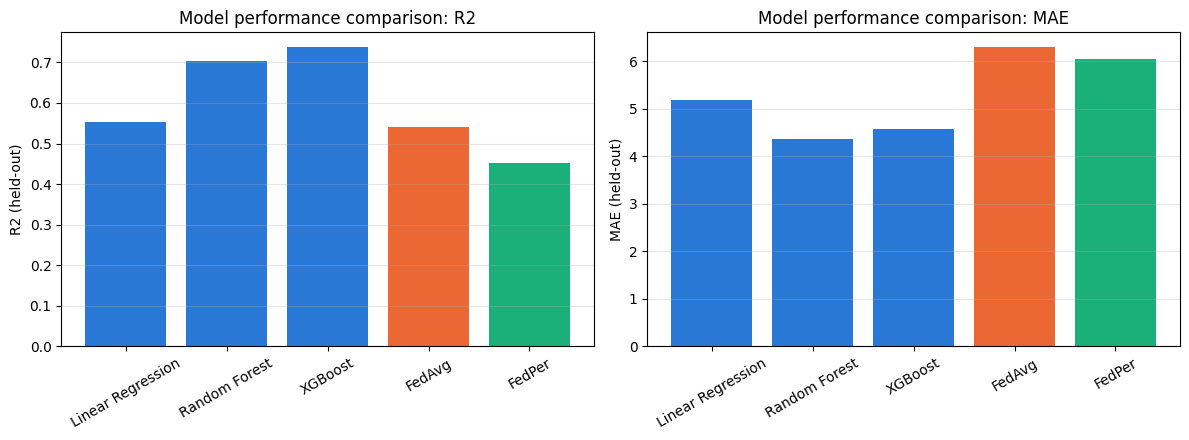

In [11]:
# Plot 1: model performance comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = [PALETTE[0]]*3 + [PALETTE[1], PALETTE[2]]
axes[0].bar(final_table["Model"], final_table["R2"], color=colors)
axes[0].set_ylabel("R2 (held-out)")
axes[0].set_title("Model performance comparison: R2")
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(axis='y', alpha=0.3)
axes[1].bar(final_table["Model"], final_table["MAE"], color=colors)
axes[1].set_ylabel("MAE (held-out)")
axes[1].set_title("Model performance comparison: MAE")
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "12_fl_model_comparison.png"), dpi=130)
plt.show()

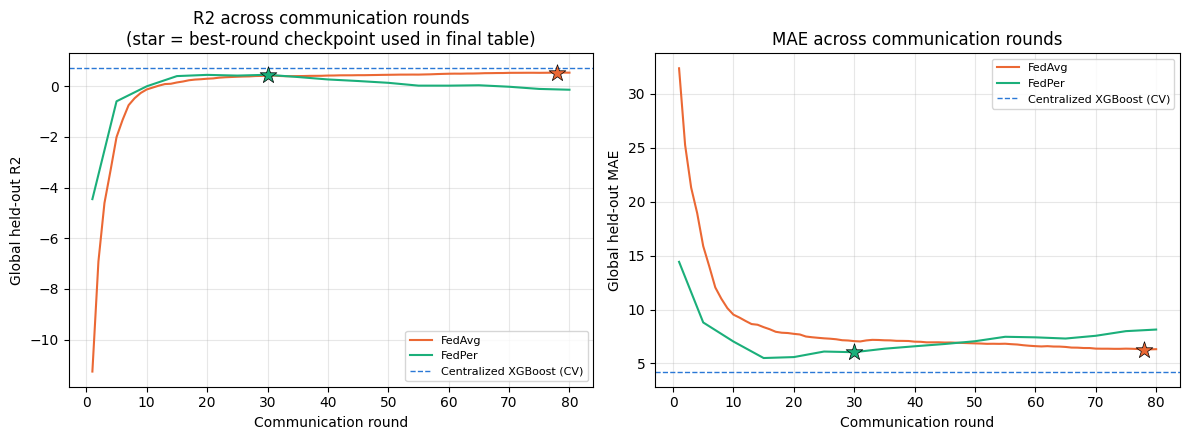

In [12]:
# Plots 2 & 3: R2 / MAE across communication rounds
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fedavg_history_df["round"], fedavg_history_df["R2"], color=PALETTE[1], lw=1.5, label="FedAvg")
axes[0].plot(fedper_history_df["round"], fedper_history_df["R2"], color=PALETTE[2], lw=1.5, label="FedPer")
axes[0].axhline(cv_results_df.loc["XGBoost", "R2_mean"], color=PALETTE[0], ls="--", lw=1, label="Centralized XGBoost (CV)")
axes[0].scatter([best_fedavg["round"]], [fedavg_final["R2"]], color=PALETTE[1], zorder=5, marker="*", s=160, edgecolor="black", linewidth=0.5)
axes[0].scatter([best_fedper["round"]], [fedper_final["R2"]], color=PALETTE[2], zorder=5, marker="*", s=160, edgecolor="black", linewidth=0.5)
axes[0].set_xlabel("Communication round")
axes[0].set_ylabel("Global held-out R2")
axes[0].set_title("R2 across communication rounds\n(star = best-round checkpoint used in final table)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(fedavg_history_df["round"], fedavg_history_df["MAE"], color=PALETTE[1], lw=1.5, label="FedAvg")
axes[1].plot(fedper_history_df["round"], fedper_history_df["MAE"], color=PALETTE[2], lw=1.5, label="FedPer")
axes[1].axhline(cv_results_df.loc["XGBoost", "MAE_mean"], color=PALETTE[0], ls="--", lw=1, label="Centralized XGBoost (CV)")
axes[1].scatter([best_fedavg["round"]], [fedavg_final["MAE"]], color=PALETTE[1], zorder=5, marker="*", s=160, edgecolor="black", linewidth=0.5)
axes[1].scatter([best_fedper["round"]], [fedper_final["MAE"]], color=PALETTE[2], zorder=5, marker="*", s=160, edgecolor="black", linewidth=0.5)
axes[1].set_xlabel("Communication round")
axes[1].set_ylabel("Global held-out MAE")
axes[1].set_title("MAE across communication rounds")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "13_fl_rounds_convergence.png"), dpi=130)
plt.show()

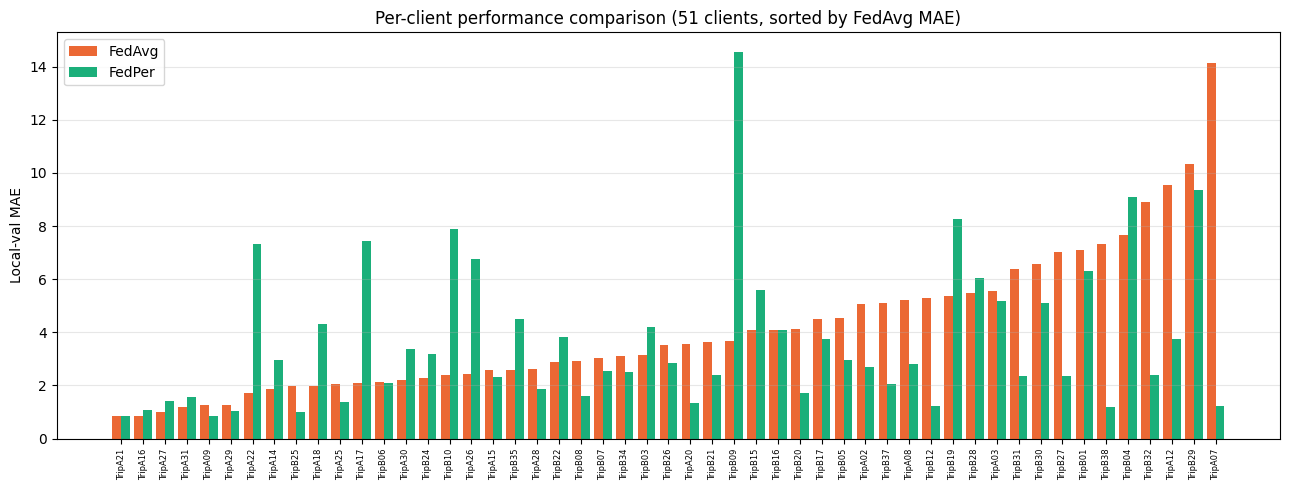

In [13]:
# Plot 4: per-client performance comparison
merged = fedavg_percli_df[["client_id", "MAE", "R2"]].merge(
    fedper_percli_df[["client_id", "MAE", "R2"]], on="client_id", suffixes=("_FedAvg", "_FedPer"))
merged = merged.sort_values("MAE_FedAvg")
fig, ax = plt.subplots(figsize=(13, 5))
xpos = np.arange(len(merged))
w = 0.4
ax.bar(xpos - w/2, merged["MAE_FedAvg"], width=w, color=PALETTE[1], label="FedAvg")
ax.bar(xpos + w/2, merged["MAE_FedPer"], width=w, color=PALETTE[2], label="FedPer")
ax.set_xticks(xpos)
ax.set_xticklabels(merged["client_id"], rotation=90, fontsize=6)
ax.set_ylabel("Local-val MAE")
ax.set_title(f"Per-client performance comparison ({len(merged)} clients, sorted by FedAvg MAE)")
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "14_fl_percli_comparison.png"), dpi=130)
plt.show()

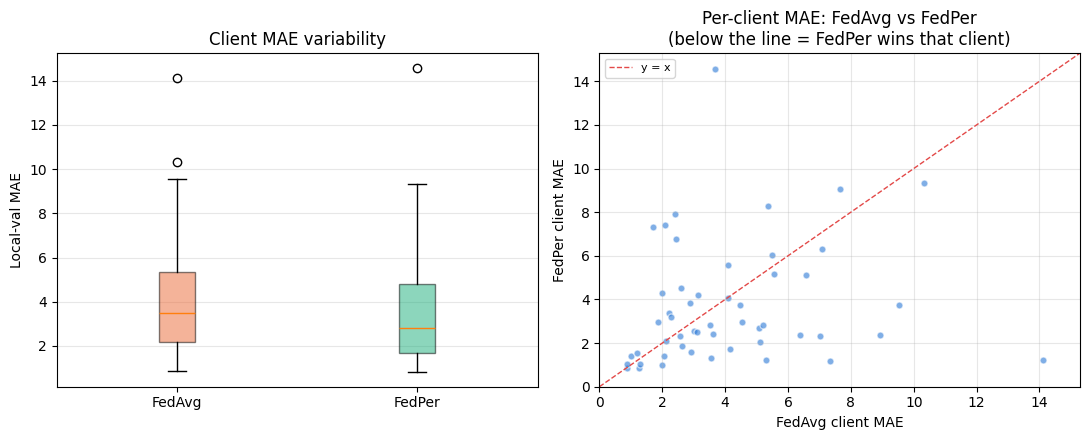

FedPer beats FedAvg on local-val MAE for 32/51 participating clients.


In [14]:
# Plot 5: FedAvg vs FedPer client variability
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
bp = axes[0].boxplot([fedavg_percli_df["MAE"], fedper_percli_df["MAE"]], tick_labels=["FedAvg", "FedPer"], patch_artist=True)
for patch, color in zip(bp['boxes'], [PALETTE[1], PALETTE[2]]):
    patch.set_facecolor(color); patch.set_alpha(0.5)
axes[0].set_ylabel("Local-val MAE")
axes[0].set_title("Client MAE variability")
axes[0].grid(axis='y', alpha=0.3)

axes[1].scatter(merged["MAE_FedAvg"], merged["MAE_FedPer"], alpha=0.6, s=25, color=PALETTE[0], edgecolor="white")
lims = [0, max(merged["MAE_FedAvg"].max(), merged["MAE_FedPer"].max()) * 1.05]
axes[1].plot(lims, lims, color=PALETTE[7], ls="--", lw=1, label="y = x")
axes[1].set_xlabel("FedAvg client MAE")
axes[1].set_ylabel("FedPer client MAE")
axes[1].set_title("Per-client MAE: FedAvg vs FedPer\n(below the line = FedPer wins that client)")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
axes[1].set_xlim(lims); axes[1].set_ylim(lims)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "15_fl_client_variability.png"), dpi=130)
plt.show()

n_fedper_better = int((merged["MAE_FedPer"] < merged["MAE_FedAvg"]).sum())
print(f"FedPer beats FedAvg on local-val MAE for {n_fedper_better}/{len(merged)} participating clients.")

## Section 7 — Research Question

> **Can federated learning predict EV battery stress nearly as effectively as centralized
> learning while keeping raw vehicle telemetry decentralized, and does personalization
> through FedPer provide an advantage over the globally shared FedAvg model?**

In [15]:
xgb_r2 = final_table.set_index("Model").loc["XGBoost", "R2"]
fedavg_r2 = final_table.set_index("Model").loc["FedAvg", "R2"]
fedper_r2 = final_table.set_index("Model").loc["FedPer", "R2"]
fedavg_mae = final_table.set_index("Model").loc["FedAvg", "MAE"]
fedper_mae = final_table.set_index("Model").loc["FedPer", "MAE"]

print("=== VERDICT (computed from this run's results) ===")
print(f"Centralized XGBoost held-out R2:            {xgb_r2:.3f}")
print(f"Centrally-trained MLP (same arch) held-out R2: {best_r2:.3f}  <- model-class ceiling for FedAvg/FedPer")
print(f"FedAvg global held-out R2:                   {fedavg_r2:.3f}  ({100*fedavg_r2/xgb_r2:.0f}% of centralized XGBoost)")
print(f"FedPer global held-out R2 (new-client, cold-start personalization): {fedper_r2:.3f}  ({100*fedper_r2/xgb_r2:.0f}% of centralized XGBoost)")
print()
print(f"FedAvg recovers {100*fedavg_r2/best_r2:.0f}% of the model-class ceiling ({best_r2:.3f}) despite never centralizing data.")
print(f"FedPer global (new-client) R2 is {'LOWER' if fedper_r2 < fedavg_r2 else 'HIGHER'} than FedAvg's "
      f"({fedper_r2:.3f} vs {fedavg_r2:.3f}) -- the cold-start personalization cost.")
print(f"But per-client (established clients): FedPer beats FedAvg on MAE for "
      f"{n_fedper_better}/{len(merged)} clients, and on median client R2 "
      f"({fedper_percli_df['R2'].median():.3f} vs {fedavg_percli_df['R2'].median():.3f}).")

=== VERDICT (computed from this run's results) ===
Centralized XGBoost held-out R2:            0.737
Centrally-trained MLP (same arch) held-out R2: 0.644  <- model-class ceiling for FedAvg/FedPer
FedAvg global held-out R2:                   0.541  (73% of centralized XGBoost)
FedPer global held-out R2 (new-client, cold-start personalization): 0.452  (61% of centralized XGBoost)

FedAvg recovers 84% of the model-class ceiling (0.644) despite never centralizing data.
FedPer global (new-client) R2 is LOWER than FedAvg's (0.452 vs 0.541) -- the cold-start personalization cost.
But per-client (established clients): FedPer beats FedAvg on MAE for 32/51 clients, and on median client R2 (0.000 vs -0.420).


### Reading the results

**1. Federated learning gets meaningfully close to centralized, but does not match it.**
FedAvg's global held-out R² sits below centralized XGBoost, but a large part of that gap
is the **model-class cost**, not a federation cost: a *centrally-trained* version of the
same small MLP tops out well below XGBoost too (Section 1). Once that's accounted for,
FedAvg recovers most of what this architecture can achieve — it is not far behind what
the same network would reach with all data pooled in one place. Federating the training
process itself, in other words, is cheaper than swapping model classes.

**2. FedPer's personalization advantage is real, but conditional.** For the 51 clients
that participated in training and built up their own head over many rounds, FedPer
produces a *better-fitting, more locally-accurate* model than the one-size-fits-all
FedAvg model — lower MAE for the majority of clients, better median R². That is a
genuine personalization win. But for the 14 held-out trips — new clients with **no
training history**, standing in for a vehicle just joining the fleet — FedPer's global
performance is *lower* than FedAvg's. Personalization has a **cold-start cost**: a head
trained on only half of one new trip's data is a weaker starting point than a single
well-generalized shared model. FedPer is the better choice for a fleet of vehicles that
have been online for a while; FedAvg is the safer choice for a fleet with high churn or
many first-time vehicles.

**3. FedPer is also less stable to train.** Its held-out performance peaks early
(around round 30 here) and then *declines* as further rounds let each client's
increasingly-specialized head pull the shared representation in idiosyncratic
directions — a real instability in personalized FL, not an artifact of this dataset.
FedAvg's curve, by contrast, climbs and plateaus cleanly. A production FedPer deployment
needs a validation-based stopping rule; a production FedAvg deployment is more forgiving
of running "too long."

**4. The single-vehicle proxy caveat matters here specifically.** Every "client" in this
notebook is a trip from the *same* car and driver (Section 2). Real fleet heterogeneity —
different driving styles, different battery packs, different climates — would very likely
make FedPer's personalization advantage **larger**, since there would be more genuine
per-client signal for a personalized head to capture than trip-to-trip variation within
one driver's habits provides. The FedPer benefit measured here should be read as a
conservative lower bound.

### The trade-off: performance ↔ privacy/decentralization ↔ personalization ↔ communication cost

| Dimension | Centralized XGBoost | FedAvg | FedPer |
|---|---|---|---|
| **Prediction performance** | Best (all data pooled, strongest model class) | Meaningfully lower — mostly the cost of a simpler model class, only partly the cost of federating | Lower still *for new clients*; **higher than FedAvg** for established, participating clients |
| **Privacy / decentralization** | None — every trip's raw telemetry must leave the vehicle | Full — only model weights ever leave the vehicle | Full for the shared base; the personalized head **never leaves the vehicle at all**, an even stronger privacy property |
| **Personalization** | None — one model fits all trips identically | None — one global model, same blind spots for every vehicle | Explicit — captures per-vehicle/per-driver differences that a shared model structurally cannot, at the cost of a cold-start period for new vehicles |
| **Communication cost** | None after initial deployment (training happens once, centrally) | Highest recurring cost — the *entire* model is transmitted every round, every client, for 80 rounds | Lower recurring cost — only the shared base is transmitted; the head (last layer) stays local, shrinking the payload |

No single row wins outright. The centralized model is the right choice when raw data
sharing is acceptable and maximum accuracy matters most — e.g. an OEM's own internal
model-development pipeline, exactly what the rest of this project builds. FedAvg is the
right choice when raw telemetry cannot leave the vehicle but every vehicle should be
treated identically (e.g. a regulator-mandated shared baseline safety model). FedPer is
the right choice when both privacy *and* per-driver personalization matter more than
squeezing out the last few points of accuracy for brand-new vehicles — e.g. an in-vehicle
driving-coach feature (this project's actual stated goal) that should get *better*, not
worse, at understanding one specific driver's habits the longer it runs on their car,
while never uploading their raw driving data anywhere.